# Car damage v2: CNN видит повреждение или качество фото?
> Продолжение `car_damage_PyTorch.ipynb`. Та же simple CNN с теми же параметрами + дообученная MobileNetV3\
> \
> Что изменилось по сравнению с первой версией:
> 1. Аудит данных: классы собраны из разных источников
> 2. Дубликаты между train и test убраны из train
> 3. Validation - отдельные 15 % от train. Test открывается один раз в конце (в v1 по тесту следили за обучением)
> 4. «Выравнивание» фото: убираем след источника и проверяем, на что опирается модель
> 5. 5 сидов на каждую постановку, сравнение моделей тестом McNemar, Grad-CAM

## Библиотеки

In [1]:
import hashlib
import io
import os
from pathlib import Path
import random
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.proportion import proportion_confint

import torch
import torch.nn as nn
from torchvision import datasets, models, transforms
from torchvision.transforms import InterpolationMode
import torch.nn.functional as F
from IPython.display import display

plt.style.use('dark_background')
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"device: {device}")

device: mps


## Фиксация генератора случайных чисел для воспроизводимости результатов

In [2]:
def seed_everything(seed: int = 42):
    start_time = time.time()

    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.mps.is_available():
        torch.mps.manual_seed(seed)

    print(f"Seed set time: {time.time() - start_time}")

## Основные параметры
> Параметры simple CNN те же, что в v1\
> MobileNetV3 предобучена, ей хватает меньше эпох и меньший шаг

In [3]:
TRAIN_DIR = 'data1a/training'
TEST_DIR = 'data1a/validation'

# simple CNN
TARGET_SIZE = (128, 128)
BATCH_SIZE = 256
EPOCHS = 150
PATIENCE = EPOCHS*0.7
MIN_DELTA = 0.001
LEARNING_RATE = 1e-3
EPSILON = 1e-6
SAVE_CHECKPOINT = False

# MobileNetV3 (transfer learning)
MN_TARGET_SIZE = (224, 224)
MN_BATCH_SIZE = 64
MN_EPOCHS = 30
MN_PATIENCE = 8
MN_LEARNING_RATE = 3e-4
MN_WEIGHT_DECAY = 1e-4

VAL_SIZE = 0.15
EQUALISE_SIDE = 192          # длинная сторона, px
EQUALISE_QUALITY = 50        # качество JPEG

SEED = 123
SEEDS = [123, 124, 125, 126, 127]
seed_everything(SEED)

Seed set time: 0.004648923873901367


## Аудит данных
> Что можно узнать о классе, вообще не глядя на машину?\
> Для каждого файла: размер в пикселях, вес в KB, регистр расширения, MD5 и dHash - 64 бита «ярче ли пиксель соседа слева» (находит ту же фотку, пережатую или уменьшенную)

In [4]:
CLASSES = ['00-damage', '01-whole']


def describe(path):
    raw = path.read_bytes()
    with Image.open(io.BytesIO(raw)) as image:
        width, height = image.size
        gray = np.asarray(image.convert('L').resize((9, 8), Image.BILINEAR), dtype=np.int16)
    return {
        'path': str(path),
        'split': 'train' if path.parts[-3] == 'training' else 'test',
        'label': CLASSES.index(path.parts[-2]),
        'class': path.parts[-2],
        'width': width,
        'height': height,
        'kb': len(raw) / 1024,
        'upper_ext': path.suffix[1:].isupper(),
        'md5': hashlib.md5(raw).hexdigest(),
        'dhash': (gray[:, 1:] > gray[:, :-1]).flatten(),
    }


files = pd.DataFrame([describe(p) for p in sorted(Path('data1a').glob('*/*/*'))])

(files.groupby(['split', 'class'])
      .agg(картинок=('path', 'size'), ширина=('width', 'median'), высота=('height', 'median'),
           KB=('kb', 'median'), доля_JPEG_капсом=('upper_ext', 'mean'))
      .round(2))

картинок  ширина  высота     KB  доля_JPEG_капсом
split class                                                       
test  00-damage       230   260.0   194.0   9.22              0.94
      01-whole        230   602.0   387.5  46.46              0.13
train 00-damage       920   260.0   194.0   8.82              0.94
      01-whole        920   580.0   368.0  44.11              0.14

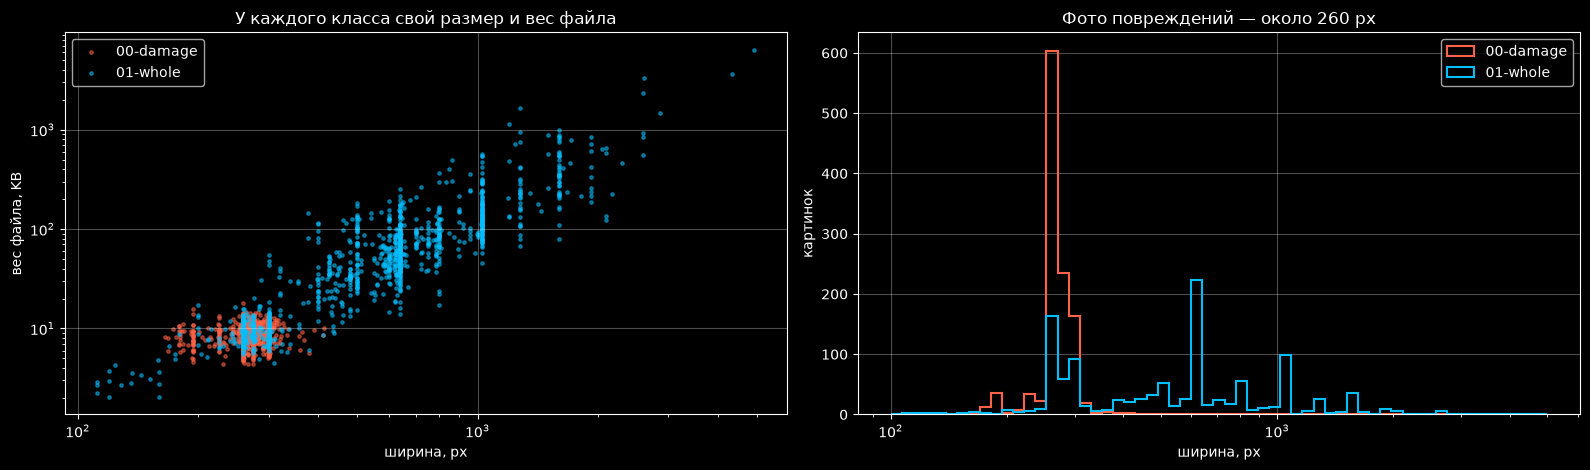

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
colors = {'00-damage': 'tomato', '01-whole': 'deepskyblue'}

for name, group in files.groupby('class'):
    ax[0].scatter(group.width, group.kb, s=6, alpha=0.5, color=colors[name], label=name)
    ax[1].hist(group.width, bins=np.geomspace(100, 5000, 60), histtype='step', lw=1.5,
               color=colors[name], label=name)

ax[0].set(xscale='log', yscale='log', xlabel='ширина, px', ylabel='вес файла, KB',
          title='У каждого класса свой размер и вес файла')
ax[1].set(xscale='log', xlabel='ширина, px', ylabel='картинок', title='Фото повреждений — около 260 px')
for axis in ax:
    axis.grid(alpha=0.3)
    axis.legend()
plt.tight_layout()
plt.show()

> Классы пришли из разных источников: **повреждения - маленькие превью** (≈ 260×194, 9 KB), **целые машины - крупные фото** в 2 раза шире и в 5 раз тяжелее. Даже расширение разное: у damage 94 % `.JPEG`, у whole 86 % `.jpg`\
> \
> Сам файл сеть не видит, но видит, что разрешение оставляет в пикселях: превью 260 px, растянутое до 128 или 224, - мягкое и с квадратами JPEG, а большое фото после уменьшения - резкое. Сеть может научиться отличать *мягкое* от *резкого* и получить высокую accuracy, ничего не поняв про вмятины

### Сколько класса сидит в метаданных
> RandomForest на 4 числах файла - ширина, высота, KB, соотношение сторон. Учим на train, проверяем на test. Ни одного пикселя

In [6]:
def metadata_features(frame, with_extension=False):
    features = pd.DataFrame({'width': frame.width, 'height': frame.height, 'kb': frame.kb,
                             'aspect': frame.width / frame.height})
    if with_extension:
        features['upper_ext'] = frame.upper_ext.astype(int)
    return features


def metadata_baseline(train, test, with_extension=False):
    forest = RandomForestClassifier(n_estimators=300, random_state=0)
    forest.fit(metadata_features(train, with_extension), train.label)
    return (forest.predict(metadata_features(test, with_extension)) == test.label).mean()


train_files = files[files.split == 'train']
test_files = files[files.split == 'test']

pd.Series({
    'всегда один класс': 0.5,
    'метаданные: ширина, высота, KB, стороны': metadata_baseline(train_files, test_files),
    'метаданные + регистр расширения': metadata_baseline(train_files, test_files, with_extension=True),
}, name='accuracy на test').round(3)

всегда один класс                          0.500
метаданные: ширина, высота, KB, стороны    0.826
метаданные + регистр расширения            0.863
Name: accuracy на test, dtype: float64

### Дубликаты
> Точные копии (одинаковый MD5) и почти-копии (dHash отличается не больше чем в 4 битах из 64)\
> Внутри train они просто перевешивают пару фото, а **между train и test - это утечка**: модель проверяют на картинках, которые она уже видела

In [7]:
exact = files[files.duplicated('md5', keep=False)].groupby('md5')
print(f'групп точных копий: {exact.ngroups}')
print(exact.apply(lambda g: ' + '.join(sorted(g.split + '/' + g['class'])), include_groups=False)
      .value_counts().to_string(), '\n')

train_hashes = np.stack(train_files.dhash.to_numpy())
test_hashes = np.stack(test_files.dhash.to_numpy())
hamming = (train_hashes[:, None, :] != test_hashes[None, :, :]).sum(axis=-1)   # (train, test)
near_pairs = np.argwhere(hamming <= 4)
print(f'почти-копий train ↔ test: {len(near_pairs)} пар, затронуто test-картинок: {len(set(near_pairs[:, 1]))}')

групп точных копий: 13
train/00-damage + train/00-damage    10
test/00-damage + train/00-damage      2
test/01-whole + train/01-whole        1 

почти-копий train ↔ test: 8 пар, затронуто test-картинок: 7


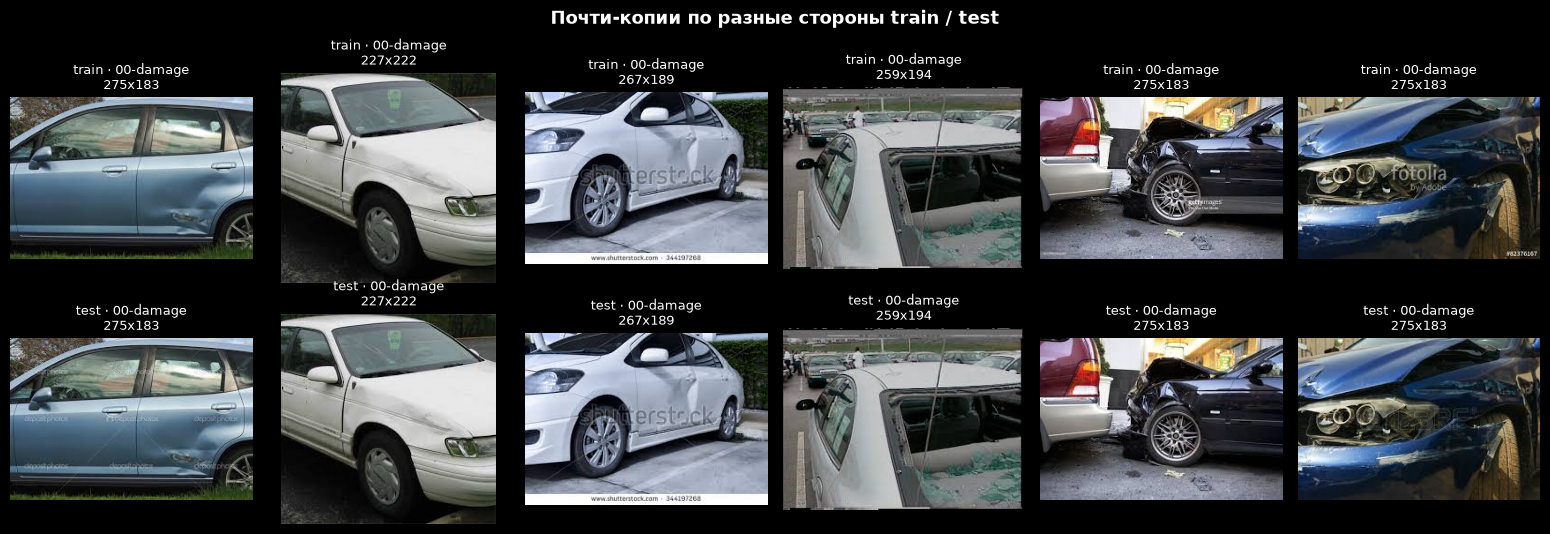

In [8]:
n_show = min(6, len(near_pairs))
fig, ax = plt.subplots(2, n_show, figsize=(2.6 * n_show, 5.4))
for column, (i, j) in enumerate(near_pairs[:n_show]):
    for row, (frame, index, name) in enumerate([(train_files, i, 'train'), (test_files, j, 'test')]):
        entry = frame.iloc[index]
        ax[row, column].imshow(Image.open(entry.path).convert('RGB'))
        ax[row, column].set_title(f"{name} · {entry['class']}\n{entry.width}x{entry.height}", fontsize=9)
        ax[row, column].axis('off')
fig.suptitle('Почти-копии по разные стороны train / test', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Чистка и разбиение train / validation / test
> **Test не трогаем** - 460 картинок как были, чтобы цифры сравнивались с v1\
> Из train убираем всё, у чего есть копия или почти-копия в test, и повторные копии внутри train\
> **Validation = 15 % от очищенного train** (стратифицированно, одно и то же для всех сидов) - по нему early stopping и выбор модели. Test - только в самом конце

In [9]:
leaking = set(train_files.index[np.unique(near_pairs[:, 0])])
leaking |= set(train_files.index[train_files.md5.isin(test_files.md5)])
clean_train = train_files.drop(index=list(leaking)).drop_duplicates('md5')

fit_files, val_files = train_test_split(clean_train, test_size=VAL_SIZE, stratify=clean_train.label,
                                        random_state=SEED)
splits = {'train': fit_files, 'val': val_files, 'test': test_files}

print(f'убрано из train: {len(train_files) - len(clean_train)} '
      f'(утечки в test: {len(leaking)}, остальное — повторные копии)')
pd.DataFrame({name: frame['class'].value_counts() for name, frame in splits.items()}).T

убрано из train: 18 (утечки в test: 8, остальное — повторные копии)


class,00-damage,01-whole
train,767,781
val,136,138
test,230,230


## «Выравнивание» фото
> Каждое фото уменьшаем до 192 px по длинной стороне и пересохраняем в JPEG с качеством 50. Меньшие не увеличиваем\
> После этого у обоих классов одно разрешение и одна история сжатия - различать их остаётся только по содержанию\
> \
> Параметры подобраны перебором (сторона 96–260 px, качество 50/75). Первая попытка, 260 px / 75, сделала **хуже**: большие фото целых машин после уменьшения оказались резче превью, которые когда-то уже растянули и пережали

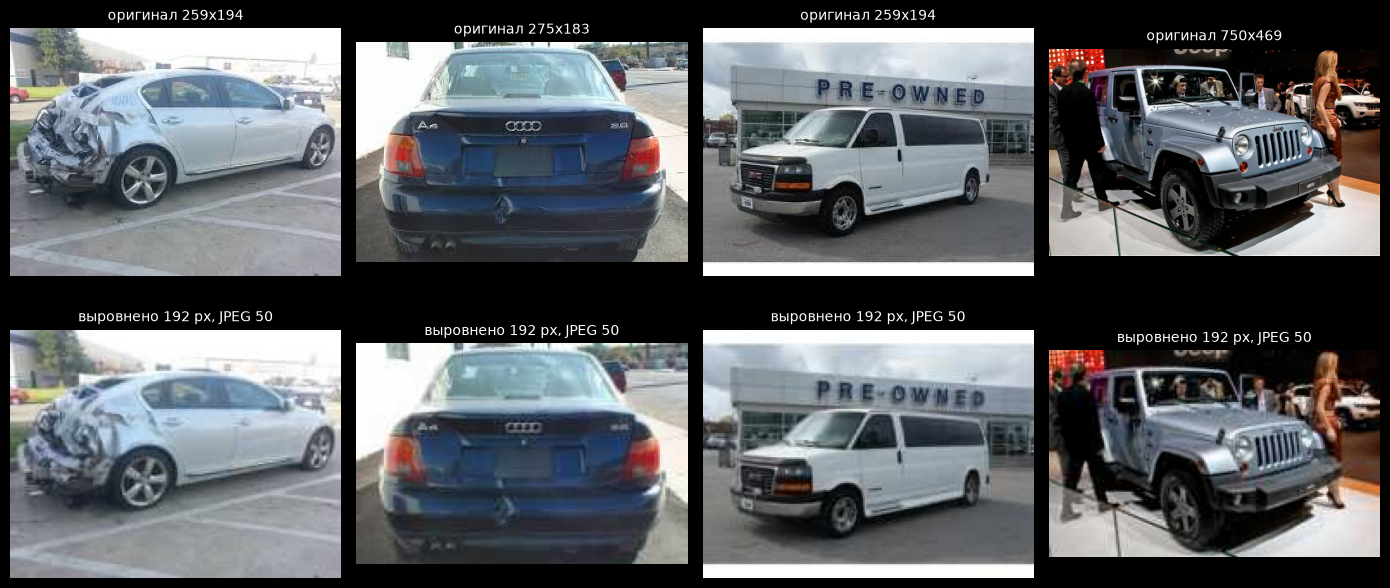

In [10]:
def equalise(image):
    # убираем след источника: одно разрешение и одно сжатие для всех
    image = image.convert('RGB')
    image.thumbnail((EQUALISE_SIDE, EQUALISE_SIDE), Image.BILINEAR)
    buffer = io.BytesIO()
    image.save(buffer, format='JPEG', quality=EQUALISE_QUALITY)
    buffer.seek(0)
    return Image.open(buffer).convert('RGB')


fig, ax = plt.subplots(2, 4, figsize=(14, 6.5))
examples = [fit_files[fit_files.label == 0].path.iloc[i] for i in (0, 1)] + \
           [fit_files[fit_files.label == 1].path.iloc[i] for i in (0, 1)]
for column, path in enumerate(examples):
    original = Image.open(path).convert('RGB')
    ax[0, column].imshow(original)
    ax[0, column].set_title(f'оригинал {original.size[0]}x{original.size[1]}', fontsize=10)
    ax[1, column].imshow(equalise(original))
    ax[1, column].set_title('выровнено 192 px, JPEG 50', fontsize=10)
for axis in ax.flat:
    axis.axis('off')
plt.tight_layout()
plt.show()

## Датасет и трансформации
> Как в v1: картинки заранее декодируются и кешируются на устройстве, батчи режутся срезами тензора (`CachedLoader`)\
> Две версии данных - **оригинал** и **выровненная**, в двух размерах - 128 для simple CNN и 224 для MobileNetV3\
> Resize - `BILINEAR` с антиалиасингом вместо `NEAREST` из v1: при уменьшении `NEAREST` просто выбрасывает пиксели и даёт алиасинг

In [11]:
class FileDataset(torch.utils.data.Dataset):
    # список файлов + трансформация; метки — в .targets, как у ImageFolder
    def __init__(self, frame, transform):
        self.paths, self.targets = list(frame.path), list(frame.label)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            return self.transform(image.convert('RGB')), self.targets[index]


def make_transform(size, equalised):
    steps = [transforms.Lambda(equalise)] if equalised else []
    steps += [transforms.Resize(size, interpolation=InterpolationMode.BILINEAR, antialias=True),
              transforms.PILToTensor()]
    return transforms.Compose(steps)


def cache_dataset(dataset):
    # Заранее кешируем картинки и кладем на устройство
    images = torch.stack([image for image, _ in dataset]).to(device)
    labels = torch.tensor(dataset.targets, device=device)
    return images, labels


class CachedLoader:
    # Замена DataLoader для датасета, целиком лежащего на устройстве
    def __init__(self, images, labels, batch_size, shuffle):
        self.images, self.labels = images, labels
        self.batch_size, self.shuffle = batch_size, shuffle

    def __len__(self):
        return (len(self.images) + self.batch_size - 1) // self.batch_size

    def __iter__(self):
        n = len(self.images)
        order = torch.randperm(n, device=self.images.device) if self.shuffle else None
        for start in range(0, n, self.batch_size):
            idx = order[start:start + self.batch_size] if self.shuffle else slice(start, start + self.batch_size)
            yield self.images[idx], self.labels[idx]


start_time = time.time()
cache = {}   # (версия, размер) -> {split: (images, labels)}
for version in ('original', 'equalised'):
    for size in (TARGET_SIZE, MN_TARGET_SIZE):
        transform = make_transform(size, equalised=version == 'equalised')
        cache[version, size] = {name: cache_dataset(FileDataset(frame, transform))
                                for name, frame in splits.items()}

total_mb = sum(images.nbytes for parts in cache.values() for images, _ in parts.values()) / 1e6
print(f'Ушло на кеш {time.time() - start_time:.1f} сек., {total_mb:.0f} мб, DEVICE: {device}')
for name, frame in splits.items():
    print(f'{name}: {len(frame)} сэмплов')

Ушло на кеш 9.4 сек., 911 мб, DEVICE: mps
train: 1548 сэмплов
val: 274 сэмплов
test: 460 сэмплов


### Что видит сеть: бейзлайн пиксельных статистик
> Метаданные сети недоступны - после resize нет ни KB, ни расширения. Доступны следы источника в самих пикселях:\
> **резкость** (дисперсия лапласиана), **энергия мелких деталей** (средний градиент), **заметность квадратов JPEG 8×8**\
> LogisticRegression на этих 3 числах - это планка, которую сеть может взять, не глядя на повреждения

In [12]:
LAPLACIAN = torch.tensor([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=torch.float32).view(1, 1, 3, 3)


def pixel_statistics(images):
    gray = images.float().cpu().mean(dim=1, keepdim=True)
    dx = (gray[..., 1:] - gray[..., :-1]).abs()
    return np.column_stack([
        np.log(F.conv2d(gray, LAPLACIAN).var(dim=(1, 2, 3)).numpy() + 1e-6),               # резкость
        np.log(dx.mean(dim=(1, 2, 3)).numpy() + 1e-6),                                        # мелкие детали
        (dx[..., 7::8].mean(dim=(1, 2, 3)) / (dx.mean(dim=(1, 2, 3)) + 1e-6)).numpy(),        # квадраты JPEG
    ])


def pixel_baseline(version):
    (train_x, train_y), (test_x, test_y) = (cache[version, MN_TARGET_SIZE][s] for s in ('train', 'test'))
    model = LogisticRegression(max_iter=1000).fit(pixel_statistics(train_x), train_y.cpu().numpy())
    return model.score(pixel_statistics(test_x), test_y.cpu().numpy())


shortcuts = pd.DataFrame({
    'оригинал': [metadata_baseline(fit_files, test_files), pixel_baseline('original')],
    'выровнено': [np.nan, pixel_baseline('equalised')],
}, index=['метаданные файла (RandomForest)', 'пиксельные статистики (что видит сеть)'])
shortcuts.round(3)

,оригинал,выровнено
метаданные файла (RandomForest),0.820,NaN
пиксельные статистики (что видит сеть),0.678,0.635


> Сеть видит меньше, чем лес по метаданным, но 68 % «бесплатно» - это много. После выравнивания планка падает, но не до 50 %: часть сигнала - уже **содержание**, а не источник. Повреждения сняты в основном крупным планом, целые машины — целиком с фоном вокруг\
> Значит, честная планка для сети ≈ 64–68 %, а не 50 %, и сравнивать модели правильно на выровненных фото

## Построение CNN
> Архитектура из v1 без изменений\
> input^3-32-64-96-128-output^192-Flatten-128-out^2
### Батчевая аугментация
> horizontal flip\
> shift ±5%\
> contrast 0.8-1.2\
> Вынесена в отдельную функцию, чтобы MobileNetV3 получала ту же самую

In [13]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)


def augment(x):
    batch = x.size(0)
    rand = lambda *shape: torch.rand(*shape, device=x.device) * 2 - 1 # [-1, 1]

    flip = torch.where(torch.rand(batch, device=x.device) < 0.5, -1.0, 1.0)
    shift = rand(batch, 2) * 0.05 * 2 # [-1, 1]: 5% = 0.1

    zeros = torch.zeros_like(flip)
    ones = torch.ones_like(flip)
    theta = torch.stack([
        torch.stack([flip, zeros, shift[:, 0]], dim=1),
        torch.stack([zeros, ones, shift[:, 1]], dim=1),
    ], dim=1) # (B, 2, 3)

    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(
        x, grid, mode="bilinear",
        padding_mode="reflection", align_corners=False,
    )

    factor = 1 + rand(batch, 1, 1, 1) * 0.2
    mean = x.mean(dim=(2, 3), keepdim=True)
    return ((x - mean) * factor + mean).clamp(0, 1)


def convolutional_block(in_channels, out_channels):
    return nn.Sequential(

        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=2),

    )


class CarDamageModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            convolutional_block(3, 32),
            convolutional_block(32, 64),
            convolutional_block(64, 96),
            nn.Dropout2d(0.1),
            convolutional_block(96, 128),
            convolutional_block(128, 192),
            nn.Dropout2d(0.2),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),

        )

        self.classifier = nn.Sequential(
            nn.Linear(192, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, 2),
        )

        for layer in self.modules():
            # инициализация Кайминга для глубоких сетей и ReLU
            if isinstance(layer, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
                if layer.bias is not None:
                    nn.init.zeros_(layer.bias)

    def forward(self, x):
        x = x.float() / 255.0

        if self.training:
            x = augment(x)

        x = (x - MEAN) / STD
        return self.classifier(self.features(x))

    def l2_loss(self):
        weights = [
            layer.weight for layer in self.modules()
            if isinstance(layer, (nn.Conv2d, nn.Linear))
        ]
        return 1e-4 * sum(weight.square().sum() for weight in weights)


print(f"Параметров: {sum(p.numel() for p in CarDamageModel().parameters()):,}")

Параметров: 432,354


## Построение MobileNetV3 (transfer learning)
> MobileNetV3-Large, предобученная на ImageNet (1,28 млн картинок), голова заменена на 2 класса, дообучаются все слои\
> Тот же интерфейс, что у CarDamageModel: на вход uint8, внутри /255, аугментация, нормализация\
> L2 здесь не отдельным слагаемым, а через `weight_decay` в AdamW - поэтому `l2_loss` возвращает 0

In [14]:
class CarDamageMobileNet(nn.Module):

    def __init__(self, pretrained=True):
        super().__init__()
        weights = models.MobileNet_V3_Large_Weights.IMAGENET1K_V2 if pretrained else None
        self.net = models.mobilenet_v3_large(weights=weights)
        self.net.classifier[-1] = nn.Linear(self.net.classifier[-1].in_features, 2)
        self.features = self.net.features    # последняя карта признаков — для Grad-CAM

    def forward(self, x):
        x = x.float() / 255.0

        if self.training:
            x = augment(x)

        x = (x - MEAN) / STD
        return self.net(x)

    def l2_loss(self):
        return torch.zeros((), device=MEAN.device)


print(f"Параметров: {sum(p.numel() for p in CarDamageMobileNet().parameters()):,}")

Параметров: 4,204,594


## Обучение
> Цикл из v1: `run_epoch` + живой график + early stopping по `val_loss` с `MIN_DELTA`\
> Отличия: validation - отдельный кусок train, а не test; после остановки **возвращаются лучшие веса** (в v1 оставались веса последней эпохи)

In [15]:
criterion = torch.nn.CrossEntropyLoss()

HISTORY_KEYS = ("loss", "acc", "precision", "recall",
                "val_loss", "val_acc", "val_precision", "val_recall", "lr")


def run_epoch(model, optimizer, loader, training):
    model.train(training)

    total_loss = 0.0
    total_samples = 0
    correct = 0
    tp = fp = fn = 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels) + model.l2_loss()

            if training:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)
            total_samples += batch_size
            total_loss += loss.detach().item() * batch_size

            with torch.no_grad():
                correct += (logits.argmax(dim=1) == labels).sum().item()

                # Precision/Recall:
                predicted = logits.softmax(dim=1) > 0.5
                actual = F.one_hot(labels, num_classes=logits.size(1)).bool()

                tp += (predicted & actual).sum().item()
                fp += (predicted & ~actual).sum().item()
                fn += (~predicted & actual).sum().item()

    return {
        "loss": total_loss / total_samples,
        "acc": correct / total_samples,
        "precision": tp / (tp + fp) if tp + fp else 0.0,
        "recall": tp / (tp + fn) if tp + fn else 0.0,
    }


def make_live_plot():
    # Виджет
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
    lines = {}
    specs = [
        (ax[0], "Loss", [("loss", "Train"), ("val_loss", "Validation")]),
        (ax[1], "Accuracy", [("acc", "Train"), ("val_acc", "Validation")]),
        (ax[2], "Learning rate", [("lr", "lr")]),
    ]
    for axis, title, series in specs:
        axis.set_title(title)
        axis.set_xlabel("Эпоха")
        axis.grid(alpha=0.3)
        for key, label in series:
            (lines[key],) = axis.plot([], [], label=label)
        axis.legend()
    plt.tight_layout()
    plt.close(fig)
    handle = display(fig, display_id=True)
    return fig, ax, lines, handle


def update_live_plot(fig, ax, lines, handle, history):
    epochs = range(1, len(history["loss"]) + 1)
    for key, line in lines.items():
        line.set_data(epochs, history[key])
    for axis in ax:
        axis.relim()
        axis.autoscale_view()
    handle.update(fig)


def fit(model, optimizer, scheduler, training_set, validation_set, epochs, patience, live=False):
    history = {name: [] for name in HISTORY_KEYS}
    best_val_loss, best_state, wait = float("inf"), None, 0
    if live:
        live_fig, live_ax, live_lines, live_handle = make_live_plot()

    for epoch in range(1, epochs + 1):
        train_metrics = run_epoch(model, optimizer, training_set, training=True)
        val_metrics = run_epoch(model, optimizer, validation_set, training=False)

        for name, value in train_metrics.items():
            history[name].append(value)
        for name, value in val_metrics.items():
            history[f"val_{name}"].append(value)
        history["lr"].append(optimizer.param_groups[0]["lr"])
        scheduler.step()

        if live:
            update_live_plot(live_fig, live_ax, live_lines, live_handle, history)

        # Earlystop + лучшие веса
        if val_metrics["loss"] < best_val_loss - MIN_DELTA:
            best_val_loss, wait = val_metrics["loss"], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                if live:
                    print(f"Earlystop на эпохе {epoch}")
                break

    model.load_state_dict(best_state)
    history["best_epoch"] = int(np.argmin(history["val_loss"])) + 1
    return history


def make_model(name):
    # модель + оптимизатор + scheduler + размер входа и батча
    if name == 'simple CNN':
        model = CarDamageModel().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, eps=EPSILON,
                                     weight_decay=0)   # L2 уже есть
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
        return model, optimizer, scheduler, TARGET_SIZE, BATCH_SIZE, EPOCHS, PATIENCE
    model = CarDamageMobileNet().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=MN_LEARNING_RATE, weight_decay=MN_WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MN_EPOCHS)
    return model, optimizer, scheduler, MN_TARGET_SIZE, MN_BATCH_SIZE, MN_EPOCHS, MN_PATIENCE


def train(name, version, seed, live=False):
    seed_everything(seed)
    model, optimizer, scheduler, size, batch, epochs, patience = make_model(name)
    data = cache[version, size]
    training_set = CachedLoader(*data['train'], batch, shuffle=True)
    validation_set = CachedLoader(*data['val'], batch, shuffle=False)
    history = fit(model, optimizer, scheduler, training_set, validation_set, epochs, patience, live)
    return model, history


@torch.no_grad()
def predict(model, images, batch=128):
    # предсказанные классы и P(damage)
    model.eval()
    probabilities = torch.cat([model(images[i:i + batch]).softmax(dim=1) for i in range(0, len(images), batch)])
    return probabilities.argmax(dim=1).cpu().numpy(), probabilities[:, 0].cpu().numpy()

### Один прогон simple CNN на выровненных фото (SEED = 123)

Seed set time: 0.0005922317504882812


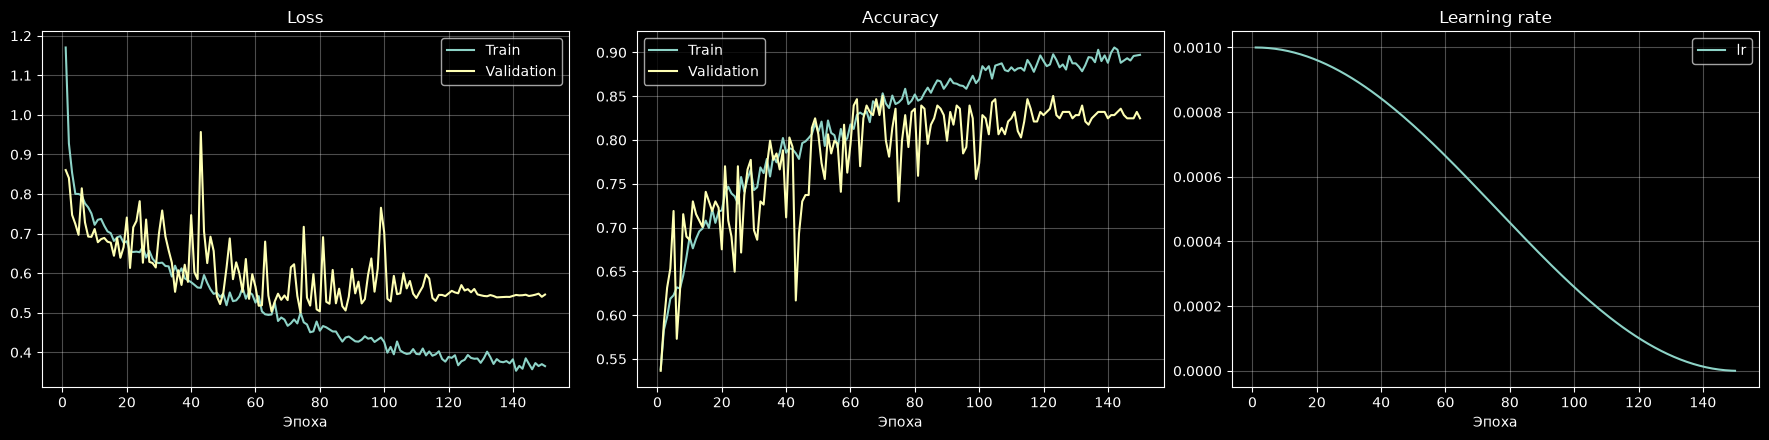

лучшая эпоха 74, val_loss 0.5004, 84 сек.


In [16]:
start_time = time.time()
model, history = train('simple CNN', 'equalised', SEED, live=True)
print(f'лучшая эпоха {history["best_epoch"]}, val_loss {min(history["val_loss"]):.4f}, '
      f'{time.time() - start_time:.0f} сек.')

> Val_loss перестаёт падать к ~75-й эпохе, дальше train продолжает снижаться, а validation стоит - начинается переобучение. Поэтому после остановки возвращаются веса лучшей эпохи, а не последней\
> Validation прыгает сильнее train: в нём всего 274 картинки

## Итоговые метрики simple CNN

In [17]:
test_images, test_labels = cache['equalised', TARGET_SIZE]['test']
y_true = test_labels.cpu().numpy()
y_pred, _ = predict(model, test_images)

print(f'Accuracy:  {accuracy_score(y_true, y_pred):.4f}\n')
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4, zero_division=0))

Accuracy:  0.8500

              precision    recall  f1-score   support

   00-damage     0.8643    0.8304    0.8470       230
    01-whole     0.8368    0.8696    0.8529       230

    accuracy                         0.8500       460
   macro avg     0.8505    0.8500    0.8499       460
weighted avg     0.8505    0.8500    0.8499       460



## Эксперимент: 2 модели × 2 версии данных × 5 сидов
> Каждую модель учим на оригинале и на выровненных фото, по 5 сидов - всего 20 прогонов\
> Каждую проверяем на **обеих** версиях test\
> Если модель опирается на след источника - на выровненном test она просядет. Если выучила повреждения - нет

In [18]:
runs, predictions, models_final = [], {}, {}
start_all = time.time()

for name in ('simple CNN', 'MobileNetV3'):
    for version in ('original', 'equalised'):
        for seed in SEEDS:
            start_time = time.time()
            run_model, run_history = train(name, version, seed)
            size = TARGET_SIZE if name == 'simple CNN' else MN_TARGET_SIZE
            for test_version in ('original', 'equalised'):
                images, labels = cache[test_version, size]['test']
                y_pred, p_damage = predict(run_model, images)
                predictions[name, version, seed, test_version] = (y_pred, p_damage)
                runs.append({'модель': name, 'учили на': version, 'сид': seed, 'test': test_version,
                             'accuracy': accuracy_score(labels.cpu().numpy(), y_pred),
                             'val_loss': min(run_history['val_loss']),
                             'лучшая эпоха': run_history['best_epoch'],
                             'сек': time.time() - start_time})
            if name == 'MobileNetV3' and version == 'equalised':
                models_final[seed] = run_model
            print(f"{name:11s} | учили на {version:9s} | сид {seed} | "
                  f"test: оригинал {runs[-2]['accuracy']:.4f}, выровнено {runs[-1]['accuracy']:.4f} | "
                  f"эпоха {run_history['best_epoch']} | {time.time() - start_time:.0f} сек.")

runs = pd.DataFrame(runs)
print(f'\n20 прогонов за {(time.time() - start_all) / 60:.1f} мин')

Seed set time: 0.0008130073547363281


simple CNN  | учили на original  | сид 123 | test: оригинал 0.8761, выровнено 0.8326 | эпоха 95 | 73 сек.
Seed set time: 0.00046515464782714844


simple CNN  | учили на original  | сид 124 | test: оригинал 0.8870, выровнено 0.8870 | эпоха 89 | 73 сек.
Seed set time: 0.0004832744598388672


simple CNN  | учили на original  | сид 125 | test: оригинал 0.8783, выровнено 0.8174 | эпоха 146 | 73 сек.
Seed set time: 0.00047206878662109375


simple CNN  | учили на original  | сид 126 | test: оригинал 0.8935, выровнено 0.8804 | эпоха 79 | 73 сек.
Seed set time: 0.0004799365997314453


...

MobileNetV3 | учили на equalised | сид 123 | test: оригинал 0.9196, выровнено 0.9196 | эпоха 4 | 31 сек.
Seed set time: 0.00046896934509277344


MobileNetV3 | учили на equalised | сид 124 | test: оригинал 0.9196, выровнено 0.9413 | эпоха 2 | 26 сек.
Seed set time: 0.0004668235778808594


MobileNetV3 | учили на equalised | сид 125 | test: оригинал 0.9174, выровнено 0.9304 | эпоха 4 | 31 сек.
Seed set time: 0.00046896934509277344


MobileNetV3 | учили на equalised | сид 126 | test: оригинал 0.9022, выровнено 0.9109 | эпоха 3 | 29 сек.
Seed set time: 0.0006778240203857422


MobileNetV3 | учили на equalised | сид 127 | test: оригинал 0.9348, выровнено 0.9217 | эпоха 2 | 26 сек.

20 прогонов за 17.5 мин


In [19]:
summary = (runs.groupby(['модель', 'учили на', 'test'])['accuracy']
               .agg(['mean', 'std']).unstack('test').round(4))
summary

mean                std         
test                  equalised original equalised original
модель      учили на                                       
MobileNetV3 equalised    0.9248   0.9187    0.0116   0.0116
            original     0.9161   0.9396    0.0209   0.0125
simple CNN  equalised    0.8557   0.8565    0.0141   0.0088
            original     0.8543   0.8783    0.0299   0.0140

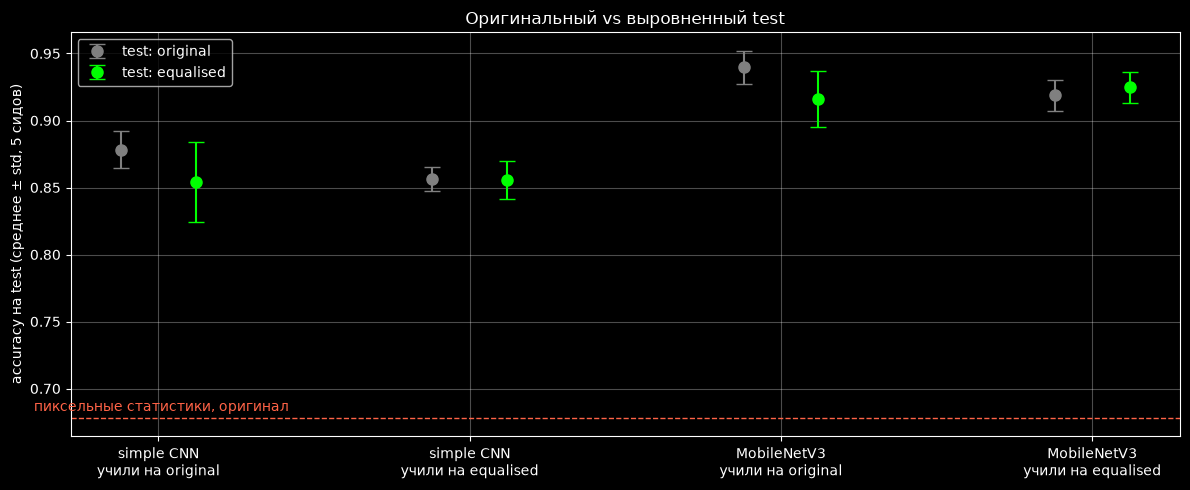

In [20]:
fig, ax = plt.subplots(figsize=(12, 5))
setups = [('simple CNN', 'original'), ('simple CNN', 'equalised'),
          ('MobileNetV3', 'original'), ('MobileNetV3', 'equalised')]
for offset, (test_version, color) in zip((-0.12, 0.12), (('original', 'grey'), ('equalised', 'lime'))):
    for position, (name, version) in enumerate(setups):
        values = runs.query('модель == @name and `учили на` == @version and test == @test_version').accuracy
        ax.errorbar(position + offset, values.mean(), yerr=values.std(), fmt='o', color=color, capsize=6,
                    markersize=8, label=f'test: {test_version}' if position == 0 else None)
ax.axhline(shortcuts.iloc[1, 0], color='tomato', ls='--', lw=1)
ax.text(-0.4, shortcuts.iloc[1, 0] + 0.005, 'пиксельные статистики, оригинал', color='tomato')
ax.set_xticks(range(4), [f'{n}\nучили на {v}' for n, v in setups])
ax.set_ylabel('accuracy на test (среднее ± std, 5 сидов)')
ax.set_title('Оригинальный vs выровненный test')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

> **Обученные на оригиналах опираются на подсказку источника.** На выровненном test simple CNN проседает с 87,8 до 85,4 % (на отдельных сидах до −6 п.п.), MobileNetV3 - с 94,0 до 91,6 % (на каждом сиде)\
> **Обученным на выровненных фото всё равно, какой test** - 85,7 / 85,6 % у CNN, 91,9 / 92,5 % у MobileNetV3. Им нечем было пользоваться\
> **Честные цифры - правые точки каждой пары:** simple CNN 85,6 % ± 1,4, MobileNetV3 92,5 % ± 1,2\
> **Предобучение - главный рычаг:** +7 п.п., и MobileNetV3 выходит на лучший val_loss за 2-7 эпох против 70-150 у CNN

### Разница между моделями - не случайность?
> На 460 картинках у accuracy стандартная ошибка ≈ ±1 п.п., так что разница в пару пунктов может быть шумом\
> Обе модели проверяются на одних и тех же картинках → парный тест **McNemar**: считает картинки, где права только одна из моделей, и проверяет, не перекошено ли это\
> Сравниваем на выровненных данных, сид против сида

In [21]:
y_true = splits['test'].label.to_numpy()
rows = []
for seed in SEEDS:
    cnn_right = predictions['simple CNN', 'equalised', seed, 'equalised'][0] == y_true
    mobile_right = predictions['MobileNetV3', 'equalised', seed, 'equalised'][0] == y_true
    table = [[np.sum(cnn_right & mobile_right), np.sum(cnn_right & ~mobile_right)],
             [np.sum(~cnn_right & mobile_right), np.sum(~cnn_right & ~mobile_right)]]
    rows.append({'сид': seed, 'права только CNN': table[0][1], 'права только MobileNet': table[1][0],
                 'McNemar p': mcnemar(table, exact=True).pvalue})
pd.DataFrame(rows).set_index('сид')

,права только CNN,права только MobileNet,McNemar p
сид,,,
123,21,54,0.000176
124,16,53,0.000009
125,18,47,0.000422
126,25,60,0.000187
127,19,44,0.002228


> На каждом сиде MobileNetV3 права на 44-60 картинках, где CNN ошиблась, и ошиблась только на 16-25, где CNN права. p от 0,00001 до 0,002 - разница в 7 п.п. между моделями не случайность выборки

## Итоговая модель
> MobileNetV3, обученная на выровненных фото. Сид выбираем **по val_loss**, а не по test

In [22]:
best_seed = runs.query("модель == 'MobileNetV3' and `учили на` == 'equalised' and test == 'equalised'") \
                .sort_values('val_loss').сид.iloc[0]
final_model = models_final[best_seed]
y_pred, p_damage = predictions['MobileNetV3', 'equalised', best_seed, 'equalised']
correct = int((y_pred == y_true).sum())
low, high = proportion_confint(correct, len(y_true), method='wilson')

print(f'сид {best_seed}: accuracy {correct / len(y_true):.4f}  (95 % интервал Уилсона {low:.4f} - {high:.4f})\n')
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4, zero_division=0))
pd.DataFrame(confusion_matrix(y_true, y_pred), index=['факт damage', 'факт whole'],
             columns=['предсказано damage', 'предсказано whole'])

сид 124: accuracy 0.9413  (95 % интервал Уилсона 0.9159 - 0.9594)

              precision    recall  f1-score   support

   00-damage     0.9552    0.9261    0.9404       230
    01-whole     0.9283    0.9565    0.9422       230

    accuracy                         0.9413       460
   macro avg     0.9417    0.9413    0.9413       460
weighted avg     0.9417    0.9413    0.9413       460



,предсказано damage,предсказано whole
факт damage,213,17
факт whole,10,220


> Сид 124 выбран по val_loss и оказался лучшим из пяти и на test - **94,1 %** (интервал 91,6-95,9 %). Поэтому для сравнения честнее брать среднее по сидам - **92,5 %**\
> Recall по damage 92,6 % при precision 95,5 %: 17 пропусков, 10 ложных тревог. Если пропуск повреждения дороже ложной тревоги (страховка, осмотр), порог 0,5 стоит сдвинуть вниз - подбирать его надо на validation, test уже использован

## Ошибки итоговой модели

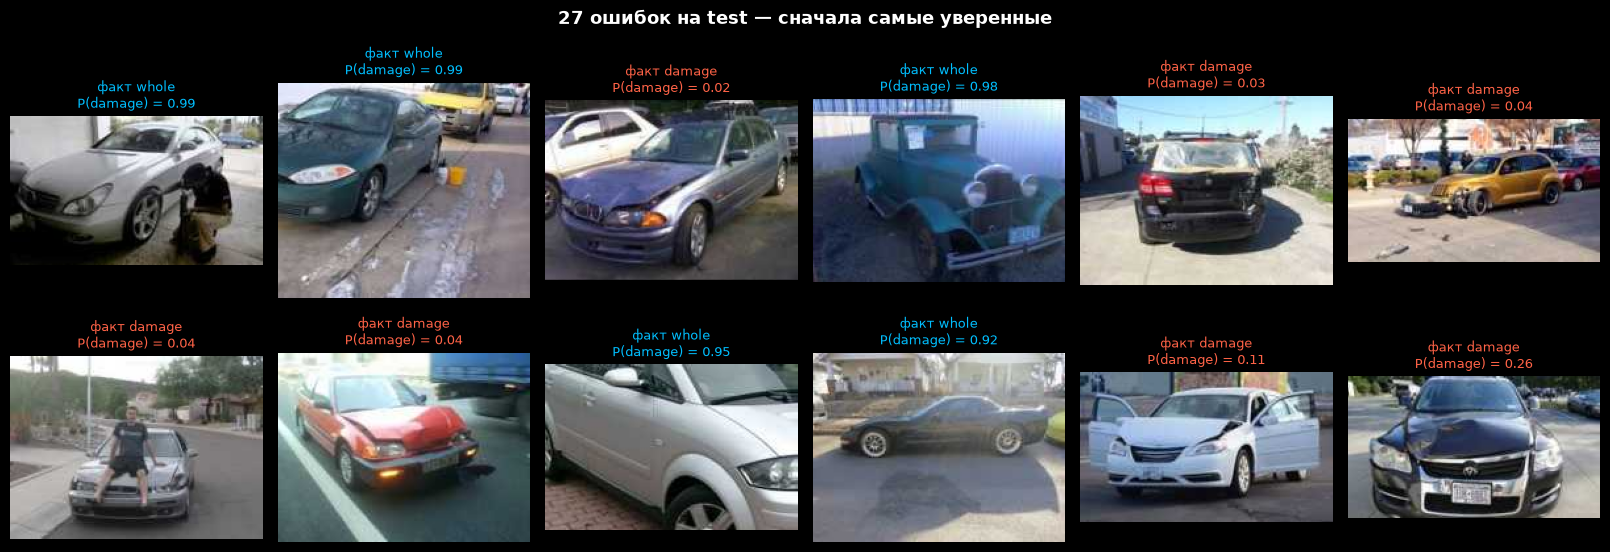

In [23]:
test_paths = list(splits['test'].path)
wrong = np.flatnonzero(y_pred != y_true)
wrong = wrong[np.argsort(-np.abs(p_damage[wrong] - 0.5))]      # сначала самые уверенные ошибки
n_show = min(12, len(wrong))
fig, ax = plt.subplots(2, (n_show + 1) // 2, figsize=(2.7 * ((n_show + 1) // 2), 6))
for axis, index in zip(ax.flat, wrong[:n_show]):
    axis.imshow(equalise(Image.open(test_paths[index])))
    axis.set_title(f'факт {CLASSES[y_true[index]][3:]}\nP(damage) = {p_damage[index]:.2f}', fontsize=9,
                   color='tomato' if y_true[index] == 0 else 'deepskyblue')
for axis in ax.flat:
    axis.axis('off')
fig.suptitle(f'{len(wrong)} ошибок на test — сначала самые уверенные', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

> Два типа ошибок:\
> **Пропуски** - повреждённая машина снята целиком, с нескольких метров, и повреждение занимает малую часть кадра (смятый перед BMW, разбитая корма, машина на эвакуаторе). Так в датасете сняты как раз целые машины\
> **Ложные тревоги** - целые машины в необычной обстановке: человек сидит на корточках у колеса, лужи и вёдра на мойке, ретро-автомобиль. Сеть выучила повреждения, но заодно и привычки датасета: *крупный план или беспорядок вокруг = битая*

## Куда смотрит сеть (Grad-CAM)
> Берём последнюю карту признаков MobileNetV3 (960 каналов, 7×7), взвешиваем каналы по тому, насколько каждый поднимает оценку класса damage, и проецируем обратно на картинку\
> Если сеть выучила повреждения - тепло должно лечь на вмятину, трещину, смятую панель, а не на фон или край кадра

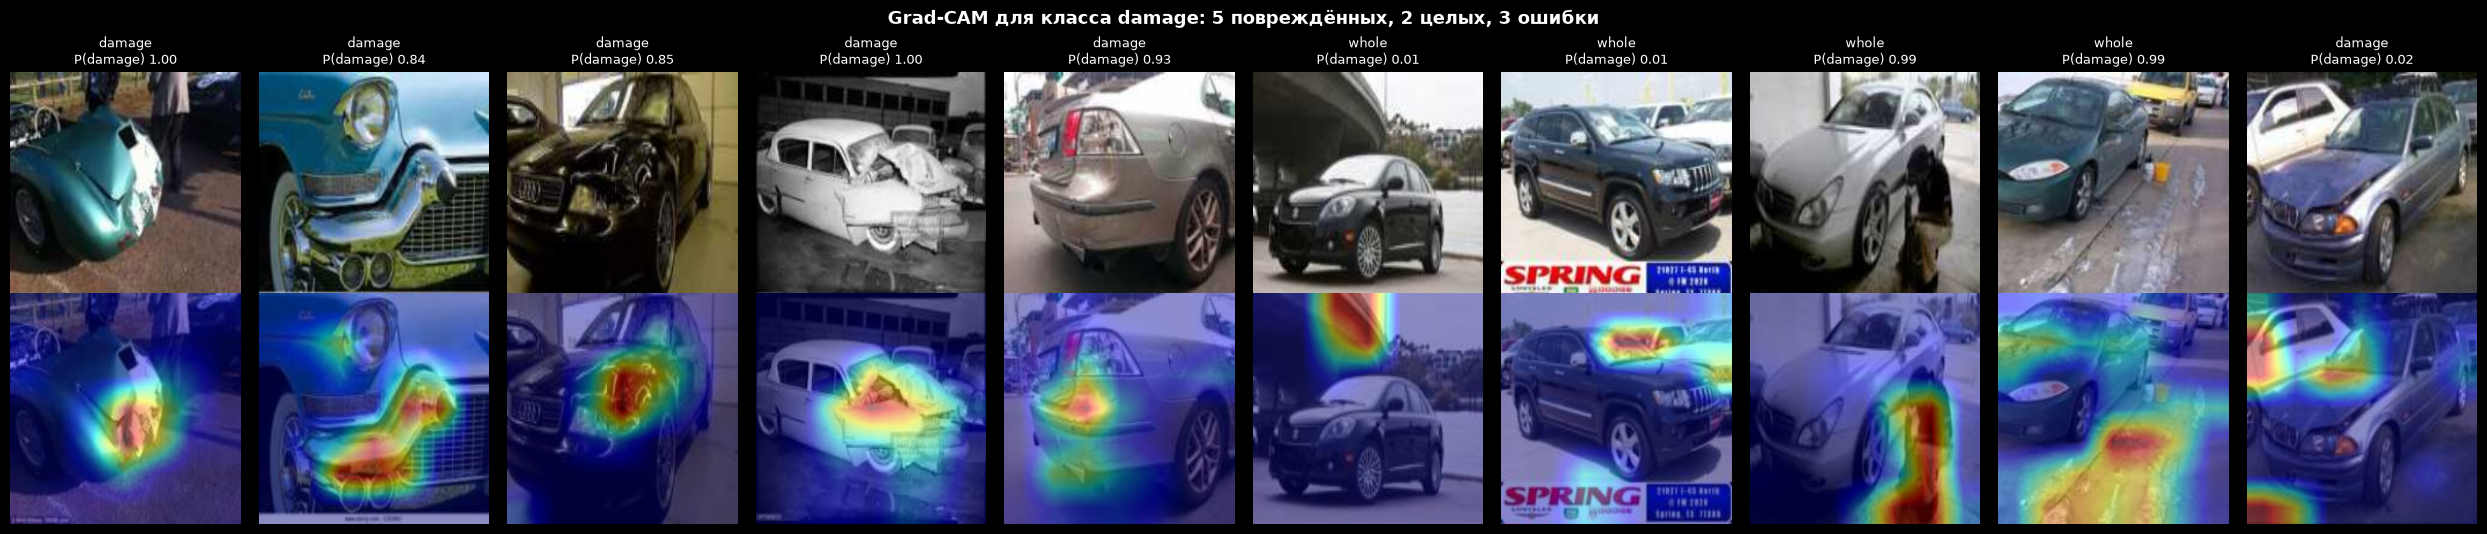

In [24]:
def grad_cam(model, image, target=0):
    model.eval()
    captured = {}
    handle = model.features.register_forward_hook(lambda module, inputs, output: captured.update(a=output))
    logits = model(image[None])
    handle.remove()

    activations = captured['a']
    gradients = torch.autograd.grad(logits[0, target], activations)[0]
    weights = gradients.mean(dim=(2, 3), keepdim=True)                # вес каждого канала
    cam = F.relu((weights * activations).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=image.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
    return (cam / (cam.max() + 1e-8)).detach().cpu().numpy(), logits.softmax(dim=1)[0].detach().cpu().numpy()


rng = np.random.default_rng(0)
right_damage = np.flatnonzero((y_pred == 0) & (y_true == 0))
right_whole = np.flatnonzero((y_pred == 1) & (y_true == 1))
picks = list(rng.choice(right_damage, min(5, len(right_damage)), replace=False)) \
        + list(rng.choice(right_whole, min(2, len(right_whole)), replace=False)) + list(wrong[:3])

images = cache['equalised', MN_TARGET_SIZE]['test'][0]
fig, ax = plt.subplots(2, len(picks), figsize=(2.5 * len(picks), 5.4))
for column, index in enumerate(picks):
    heat, probabilities = grad_cam(final_model, images[index])
    picture = images[index].permute(1, 2, 0).cpu().numpy()
    ax[0, column].imshow(picture)
    ax[0, column].set_title(f'{CLASSES[y_true[index]][3:]}\nP(damage) {probabilities[0]:.2f}', fontsize=9)
    ax[1, column].imshow(picture)
    ax[1, column].imshow(heat, cmap='jet', alpha=0.45)
for axis in ax.flat:
    axis.axis('off')
fig.suptitle('Grad-CAM для класса damage: 5 повреждённых, 2 целых, 3 ошибки', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

> **На правильных повреждениях** тепло лежит на самой деформации: смятое крыло, бампер, разбитый перед\
> **На ошибках** - не на машине: на мокром асфальте и вёдрах вокруг, на человеке у колеса, на земле перед бампером. Сеть связала «беспорядок вокруг машины» с повреждением - в train такие сцены чаще встречаются у битых машин\
> На целых машинах карта почти пустая или уходит в фон (небо, рекламный баннер) - при P(damage) ≈ 0 это просто шум

## Сохранение модели для демо
> В чекпойнте вместе с весами - параметры выравнивания, чтобы демо готовило фото так же, как при обучении

In [25]:
checkpoint_path = Path('models') / 'car_damage_mobilenetv3_2026-10-25.pt'
checkpoint_path.parent.mkdir(exist_ok=True)
torch.save({
    'model_state_dict': final_model.state_dict(),
    'classes': CLASSES,
    'target_size': MN_TARGET_SIZE,
    'equalise_side': EQUALISE_SIDE,
    'equalise_quality': EQUALISE_QUALITY,
    'seed': int(best_seed),
    'test_accuracy': correct / len(y_true),
}, checkpoint_path)

reloaded = CarDamageMobileNet(pretrained=False).to(device)
reloaded.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True)['model_state_dict'])
assert (predict(reloaded, images)[0] == y_pred).all(), 'после загрузки предсказания изменились'
print(f'Сохранено: {checkpoint_path} ({checkpoint_path.stat().st_size / 1e6:.1f} мб), загрузка проверена')

Сохранено: models/car_damage_mobilenetv3_2026-10-25.pt (17.1 мб), загрузка проверена


## Результат
> **1. В данных была подсказка.** Классы собраны из разных источников: по размеру и весу файла класс угадывается в 82 % случаев, по 3 пиксельным статистикам - в 68 %. Без единого взгляда на повреждение\
> \
> **2. Модели ею пользовались.** Обученные на оригиналах теряют в среднем 2,4 п.п., как только подсказку убирают из test: simple CNN 87,8 → 85,4 %, MobileNetV3 94,0 → 91,6 %\
> \
> **3. Честные цифры** (учили и проверяли на выровненных фото, 5 сидов):\
> simple CNN - **85,6 % ± 1,4**\
> MobileNetV3 - **92,5 % ± 1,2**\
> MobileNetV3 лучше на каждом сиде, McNemar p ≤ 0,002. Предобучение на ImageNet даёт +7 п.п. на 1 500 фото\
> \
> **4. Сравнение с v1.** 90,65 % simple CNN в v1 - это примерно 85–86 % честных + подсказка источника + выбор по test (validation = test). Архитектура и параметры те же\
> \
> **5. Модель смотрит на повреждения** - Grad-CAM на правильных ответах ложится на смятые панели. Слабые места: повреждение мелкое в кадре (машина снята целиком издалека) и «беспорядок» вокруг целой машины - лужи, вёдра, человек рядом\
> \
> Что дальше: больше фото повреждённых машин целиком, аугментация random crop / zoom, порог под recall по damage, подобранный на validation